# 08 — Pre-modelling bias audit

Phase 1, Step 5 of the thesis: characterise group-level disparities in outcomes, representation, missingness and proxies in the data before modelling, and state what these do and do not imply about historical bias. The notebook works on `application_train.csv` and on the engineered features in `artifacts/features/` (built from all relational tables), for gender, the 10-year age bands and the 10 gender × age cells.

## Purpose

- How are the groups represented, and how entangled are gender and age?
- How large are the outcome (`TARGET`) disparities between groups, with uncertainty, and do they persist within age bands and within payment-to-income (PTI) quintiles?
- Is missingness, including missing credit history, spread unevenly across groups, and is it related to the outcome?
- Which features act as proxies for gender or age, alone or jointly?
- What do these findings imply, and not imply, about historical bias?

**Context:** [07_protected_attributes.ipynb](07_protected_attributes.ipynb) (its sections 1–5 are repeated here, with intervals) · [docs/decisions.md](../../docs/decisions.md) · helpers in [analysis/helpers/data_audit.py](../helpers/data_audit.py)

**Requires:** Home Credit CSVs in `data/` and the stage-1 feature artifacts (`python -m src.features.pipeline --data-dir data --artifacts-dir artifacts/features`).

## Conventions

- `TARGET = 1` = payment difficulties (default); `TARGET = 0` = repaid, the favourable label. Signed gaps are written `a − b` (e.g. F − M).
- 95% intervals: plug-in binomial for rates, Wald for differences, delta method on the log scale for ratios, and Lum et al.'s (2022) double-corrected within-group bootstrap (B = 500) for summaries over many groups. P-values come after gaps and intervals and are not corrected for multiplicity (all gaps here are descriptive; `docs/decisions.md`).
- Every number describes the labelled data, not the decisions of a credit scorer.

## Out of scope

- Credit-scoring model training and fairness metrics on predictions (Phase 1, Step 6)
- Mitigation (pre / in / post)
- The auxiliary classifier in §5.3 predicts gender, not default. It measures how much gender is encoded in the features and is not a credit scorer.

---

## 0. Setup and audit constants

Load the application tables and the model configuration, and fix the groups, orderings and proxy candidates used throughout. The statistics live in `analysis/helpers/data_audit.py`; age bands reuse the pipeline definition in `src/features/application.py`.

In [4]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

_cwd = Path.cwd()
if not (_cwd / "data" / "application_train.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "application_train.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from analysis.helpers.data_audit import (  # noqa: E402
    association_profile,
    cmh_test,
    correlation_ratio,
    cramers_v,
    feldman_ber_threshold,
    missing_rate_by_group,
    outcome_by_missingness,
    pairwise_gaps,
    proportion_gap,
    proportion_table,
    protected_attribute_predictability,
    worst_group_summary,
)
from src.constants import (  # noqa: E402
    AGE_BAND_COL,
    AGE_BAND_EDGES,
    AGE_YEARS_COL,
    DAYS_PER_YEAR,
    DAYS_SENTINEL,
    INTERSECTION_COL,
    PROTECTED_ATTRIBUTES,
)
from src.features.application import assign_age_band  # noqa: E402
from src.models.io import load_yaml_config  # noqa: E402

DATA_DIR = Path("data")
FEATURES_DIR = Path("artifacts/features")
MODEL_CONFIG_PATH = Path("configs/model.yaml")
PRIMARY_KEY = "SK_ID_CURR"
GENDER_COL = "CODE_GENDER"
TARGET = "TARGET"
REPAID = "REPAID"  # 1 - TARGET, the favourable label

model_config = load_yaml_config(MODEL_CONFIG_PATH)
SEED = int(model_config["seed"])
N_BOOT = 500

GENDER_ORDER = ["F", "M"]
BAND_ORDER = [f"{lo}-{hi - 1}" for lo, hi in zip(AGE_BAND_EDGES[:-1], AGE_BAND_EDGES[1:])]
CELL_ORDER = [f"{g} | {b}" for g in GENDER_ORDER for b in BAND_ORDER]
GENDER_COLORS = {"F": "steelblue", "M": "coral"}

# Conditioning variable W for conditional gaps (docs/decisions.md):
# PTI = AMT_ANNUITY / AMT_INCOME_TOTAL, quintiles on the full sample.
PTI_COL = "PTI"
PTI_Q_COL = "PTI_QUINTILE"
PTI_DECIDED_CUTS = [0.104, 0.144, 0.186, 0.247]

# Proxy candidates carried over from 07_protected_attributes
PROXY_CATEGORICAL = [
    "NAME_EDUCATION_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "NAME_CONTRACT_TYPE",
    "FLAG_OWN_CAR",
    "REGION_RATING_CLIENT",
]
PROXY_NUMERIC = [
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE",
    "OWN_CAR_AGE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
]

train = pd.read_csv(DATA_DIR / "application_train.csv")
test = pd.read_csv(DATA_DIR / "application_test.csv")

assert train[PRIMARY_KEY].is_unique and test[PRIMARY_KEY].is_unique
assert TARGET in train.columns and TARGET not in test.columns
assert set(PROTECTED_ATTRIBUTES).issubset(train.columns)

print(f"Protected attributes: {PROTECTED_ATTRIBUTES}")
print(f"Seed: {SEED}, bootstrap samples: {N_BOOT}")
print(f"train: {train.shape[0]:,} rows x {train.shape[1]} cols")
print(f"test:  {test.shape[0]:,} rows x {test.shape[1]} cols")

Protected attributes: ['CODE_GENDER', 'DAYS_BIRTH']
Seed: 42, bootstrap samples: 500
train: 307,511 rows x 122 cols
test:  48,744 rows x 121 cols


---

## 1. Sample definition and group labels

Document the `XNA` exclusion, build the age-band and gender × age labels, and check that they match the fairness groups written by the feature pipeline, so that this audit and the model audit (Step 6) use the same rows and cells.

In [5]:
xna_rows = train.loc[train[GENDER_COL] == "XNA", [PRIMARY_KEY, GENDER_COL, TARGET, "DAYS_BIRTH"]]
print("XNA rows in train:")
display(xna_rows)

audit = train[train[GENDER_COL] != "XNA"].reset_index(drop=True)
test_audit = test[test[GENDER_COL] != "XNA"].reset_index(drop=True)
for df in (audit, test_audit):
    df[AGE_YEARS_COL] = -df["DAYS_BIRTH"] / DAYS_PER_YEAR
    df[AGE_BAND_COL] = assign_age_band(df["DAYS_BIRTH"]).astype(str)
    df[INTERSECTION_COL] = df[GENDER_COL].astype(str) + " | " + df[AGE_BAND_COL]
audit[REPAID] = 1 - audit[TARGET]

pipeline_groups = pd.read_parquet(FEATURES_DIR / "fairness_groups_train.parquet")
merged = audit[[PRIMARY_KEY, INTERSECTION_COL]].merge(
    pipeline_groups[[PRIMARY_KEY, INTERSECTION_COL]], on=PRIMARY_KEY, how="outer",
    suffixes=("_audit", "_pipeline"), indicator=True,
)
group_check = pd.Series(
    {
        "rows_audit": len(audit),
        "rows_pipeline": len(pipeline_groups),
        "ids_only_in_one_source": int((merged["_merge"] != "both").sum()),
        "cell_label_mismatches": int(
            (merged[f"{INTERSECTION_COL}_audit"] != merged[f"{INTERSECTION_COL}_pipeline"]).sum()
        ),
    }
)
print("Audit sample vs artifacts/features/fairness_groups_train.parquet:")
display(group_check.to_frame("value"))
assert group_check["ids_only_in_one_source"] == 0 and group_check["cell_label_mismatches"] == 0

XNA rows in train:


,SK_ID_CURR,CODE_GENDER,TARGET,DAYS_BIRTH
35657,141289,XNA,0,-20232
38566,144669,XNA,0,-13717
83382,196708,XNA,0,-10647
189640,319880,XNA,0,-9649


Audit sample vs artifacts/features/fairness_groups_train.parquet:


,value
rows_audit,307507
rows_pipeline,307507
ids_only_in_one_source,0
cell_label_mismatches,0


**Interpretation:** `XNA` appears in 4 train rows and in no test row, and all 4 have `TARGET = 0`. As in notebook 07 they are excluded as an exclusion forced by the data, leaving 307,507 rows. The audit sample and the pipeline's `fairness_groups_train.parquet` have the same IDs and the same gender × age labels, so every figure below refers to the rows and cells that Step 6 evaluates.

---

## 2. Representation

Describe how large each group and cell is, how many positives and negatives each holds (the denominators of FNR and FPR in Step 6), how gender and age are entangled, and whether train and test have the same mix. There is no external population benchmark, so representativeness can only be checked inside the data.

Define a small helper that compares normalized group shares between the training and test audit samples. Compare the share of women and men in train versus test (percent of rows and absolute train–test difference in percentage points).


In [11]:
def representation_table(train_df: pd.DataFrame, test_df: pd.DataFrame, col: str) -> pd.DataFrame:
    tr = 100 * train_df[col].value_counts(normalize=True)
    te = 100 * test_df[col].value_counts(normalize=True)
    out = pd.DataFrame({"train_share": tr, "test_share": te}).fillna(0)
    out["abs_diff_pp"] = (out["train_share"] - out["test_share"]).abs()
    return out.sort_index()
print(f"Representation train vs test: {GENDER_COL}")
display(representation_table(audit, test_audit, GENDER_COL).round(2))


Representation train vs test: CODE_GENDER


,train_share,test_share,abs_diff_pp
CODE_GENDER,,,
F,65.84,67.04,1.2
M,34.16,32.96,1.2


Compare the share of each 10-year age band in train versus test using the same table.


In [21]:
print(f"Representation train vs test: {AGE_BAND_COL}")
display(representation_table(audit, test_audit, AGE_BAND_COL).round(2))


Representation train vs test: AGE_BAND


,train_share,test_share,abs_diff_pp
AGE_BAND,,,
20-29,14.69,14.11,0.58
30-39,26.77,26.90,0.13
40-49,24.91,25.62,0.71
50-59,22.14,21.70,0.45
60-69,11.48,11.67,0.19


Compare gender × age cell shares between train and test so no intersectional cell drifts across splits.


In [22]:
print(f"Representation train vs test: {INTERSECTION_COL}")
display(representation_table(audit, test_audit, INTERSECTION_COL).round(2))


Representation train vs test: GENDER_AGE


,train_share,test_share,abs_diff_pp
GENDER_AGE,,,
F | 20-29,8.34,7.51,0.83
F | 30-39,16.30,16.95,0.65
F | 40-49,16.14,17.18,1.04
F | 50-59,16.05,15.98,0.07
F | 60-69,9.01,9.42,0.41
M | 20-29,6.35,6.60,0.25
M | 30-39,10.47,9.95,0.52
M | 40-49,8.77,8.44,0.33
M | 50-59,6.10,5.72,0.38


Summarize age in years on the training audit sample by gender (counts, mean, and quartiles).


In [23]:
print("Age in years by gender (train):")
display(audit.groupby(GENDER_COL)[AGE_YEARS_COL].describe().round(2))


Age in years by gender (train):


,count,mean,std,min,25%,50%,75%,max
CODE_GENDER,,,,,,,,
F,202448.0,45.18,12.04,20.50,35.33,44.83,55.43,69.07
M,105059.0,41.45,11.38,21.02,32.03,40.26,50.04,68.98


For each age band, compute the percentage of applicants who are women and contrast it with the overall female share.


In [24]:
female_share_by_band = (
    audit.groupby(AGE_BAND_COL)[GENDER_COL].apply(lambda s: (s == "F").mean()).reindex(BAND_ORDER)
)
print("Share of women within each age band (train):")
display((100 * female_share_by_band).round(2).rename("pct_female").to_frame())


Share of women within each age band (train):


,pct_female
AGE_BAND,
20-29,56.77
30-39,60.88
40-49,64.80
50-59,72.47
60-69,78.45


Plot the training-sample age distribution by gender (density, separate normalization), with 10-year band edges marked.


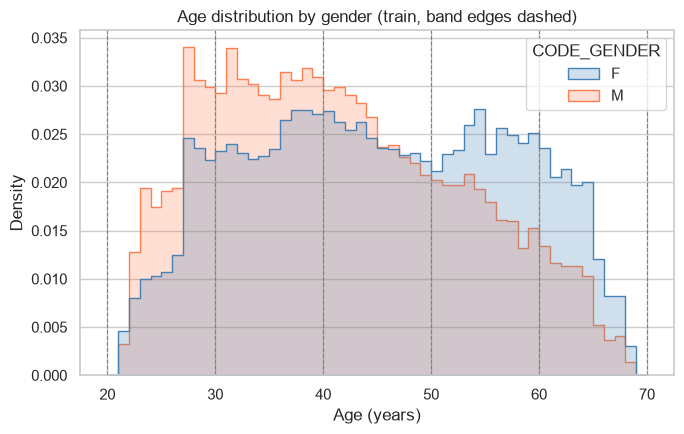

In [25]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(
    data=audit, x=AGE_YEARS_COL, hue=GENDER_COL, hue_order=GENDER_ORDER, palette=GENDER_COLORS,
    bins=np.arange(20, 71, 1), element="step", stat="density", common_norm=False, ax=ax,
)
for edge in AGE_BAND_EDGES:
    ax.axvline(edge, color="grey", lw=0.8, ls="--")
ax.set_title("Age distribution by gender (train, band edges dashed)")
ax.set_xlabel("Age (years)")
plt.tight_layout()
plt.show()


Bar chart of the share of women within each age band on the training sample, with the overall female share as a dashed reference.


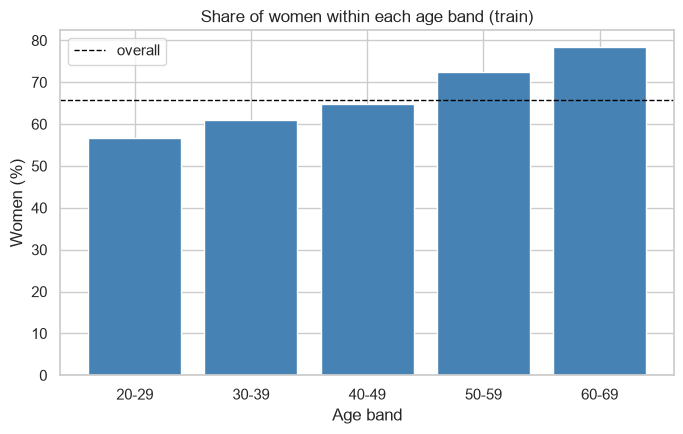

In [26]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(BAND_ORDER, 100 * female_share_by_band.values, color=GENDER_COLORS["F"])
ax.axhline(100 * (audit[GENDER_COL] == "F").mean(), color="black", lw=1, ls="--", label="overall")
ax.set_title("Share of women within each age band (train)")
ax.set_xlabel("Age band")
ax.set_ylabel("Women (%)")
ax.legend()
plt.tight_layout()
plt.show()


Heatmap of row counts per gender × age cell on the training sample (same cells as in the table below).


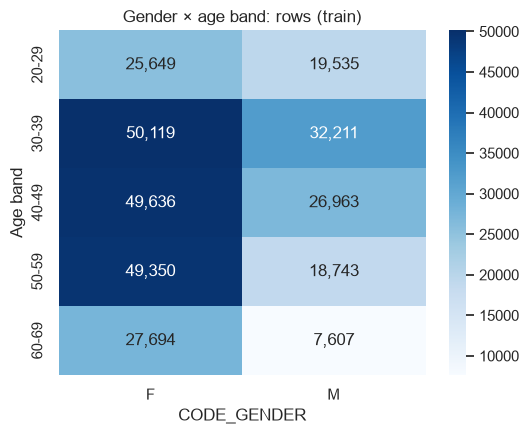

In [27]:
cell_counts = (
    audit.groupby([AGE_BAND_COL, GENDER_COL])[TARGET].agg(n="size", positives="sum")
    .assign(negatives=lambda d: d["n"] - d["positives"])
)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cell_counts["n"].unstack(GENDER_COL).reindex(BAND_ORDER),
    annot=True,
    fmt=",.0f",
    cmap="Blues",
    ax=ax,
)
ax.set_title("Gender × age band: rows (train)")
ax.set_ylabel("Age band")
plt.tight_layout()
plt.show()


Tabulate row counts, default positives (`TARGET = 1`), and negatives per gender × age cell; these denominators feed rate-based fairness metrics in Step 6.


In [28]:
print("Positives and negatives per gender × age cell (train):")
display(cell_counts.unstack(GENDER_COL).reindex(BAND_ORDER))


Positives and negatives per gender × age cell (train):


n        positives       negatives       
CODE_GENDER      F      M         F     M         F      M
AGE_BAND                                                  
20-29        25649  19535      2725  2446     22924  17089
30-39        50119  32211      4365  3532     45754  28679
40-49        49636  26963      3313  2540     46323  24423
50-59        49350  18743      2517  1651     46833  17092
60-69        27694   7607      1250   486     26444   7121

**Interpretation:**

- **Gender and age are entangled.** Women are 65.8% of applicants and older on average (median 44.8 vs 40.3 years). Their share rises from 56.8% in 20–29 to 78.5% in 60–69, so any comparison by gender alone partly compares age groups.
- **Cell sizes.** The largest cell is `F | 30-39` (50,119 rows). The smallest is `M | 60-69` (7,607 rows, 486 positives, 7,121 negatives).
- **Train vs test.** No gender, age-band or cell share differs by more than 1.2 pp, so the test mix does not change the picture.
- **What this cannot show.** The data has no population benchmark. It cannot tell whether women, men or any age group are under-represented among applicants, or among granted loans, relative to the population Home Credit serves.

---

## 3. Outcome disparities in `TARGET`

Measure the default rate of each group with 95% intervals, the signed gaps and ratios between groups, and whether the gender gap persists after stratifying by age band or by PTI. These describe the labels, which a model trained on them will learn to reproduce.

### 3.1 Gender

Default and repayment rates by gender, the F − M gap, and two ratios: the default-rate ratio M / F and the repayment-rate ratio M / F. The repayment ratio is the label-level analogue of the disparate impact ratio on approvals (lower rate over higher rate; 0.8 is the four-fifths reference).

In [4]:
gender_rates = proportion_table(audit, [GENDER_COL], TARGET).reindex(GENDER_ORDER)
print("Default rate by gender (train):")
display(gender_rates.round(4))

f, m = gender_rates.loc["F"], gender_rates.loc["M"]
gender_gap_default = proportion_gap(f["rate"], f["n"], m["rate"], m["n"])
gender_ratio_default = proportion_gap(m["rate"], m["n"], f["rate"], f["n"])
gender_ratio_repaid = proportion_gap(1 - m["rate"], m["n"], 1 - f["rate"], f["n"])
gender_summary = pd.DataFrame(
    {
        "estimate": [gender_gap_default["diff"], gender_ratio_default["ratio"], gender_ratio_repaid["ratio"]],
        "ci_low": [gender_gap_default["diff_ci_low"], gender_ratio_default["ratio_ci_low"], gender_ratio_repaid["ratio_ci_low"]],
        "ci_high": [gender_gap_default["diff_ci_high"], gender_ratio_default["ratio_ci_high"], gender_ratio_repaid["ratio_ci_high"]],
        "p_value": [gender_gap_default["p_value"], np.nan, np.nan],
    },
    index=["default gap F − M", "default ratio M / F", "repaid ratio M / F"],
)
print("Gender gap and ratios (train):")
display(gender_summary.round(4))

Default rate by gender (train):


,n,events,non_events,share,rate,se,ci_low,ci_high
CODE_GENDER,,,,,,,,
F,202448,14170,188278,0.6584,0.0700,0.0006,0.0689,0.0711
M,105059,10655,94404,0.3416,0.1014,0.0009,0.0996,0.1032


Gender gap and ratios (train):


,estimate,ci_low,ci_high,p_value
default gap F − M,-0.0314,-0.0336,-0.0293,0.0
default ratio M / F,1.4490,1.4146,1.4842,NaN
repaid ratio M / F,0.9662,0.9639,0.9685,NaN


### 3.2 Age band

Default rate by 10-year band, and the 20–29 vs 60–69 gap that the decisions log fixes as the age comparison.

In [5]:
band_rates = proportion_table(audit, [AGE_BAND_COL], TARGET).reindex(BAND_ORDER)
print("Default rate by age band (train):")
display(band_rates.round(4))

band_pair = pairwise_gaps(band_rates, [("20-29", "60-69")])
print("Age gap 20–29 − 60–69 (default rate) and ratio 20–29 / 60–69:")
display(band_pair.round(4))

Default rate by age band (train):


,n,events,non_events,share,rate,se,ci_low,ci_high
AGE_BAND,,,,,,,,
20-29,45184,5171,40013,0.1469,0.1144,0.0015,0.1115,0.1174
30-39,82330,7897,74433,0.2677,0.0959,0.0010,0.0939,0.0979
40-49,76599,5853,70746,0.2491,0.0764,0.0010,0.0745,0.0783
50-59,68093,4168,63925,0.2214,0.0612,0.0009,0.0594,0.0630
60-69,35301,1736,33565,0.1148,0.0492,0.0012,0.0469,0.0514


Age gap 20–29 − 60–69 (default rate) and ratio 20–29 / 60–69:


,group_a,group_b,rate_a,rate_b,n_a,n_b,diff,diff_ci_low,diff_ci_high,p_value,ratio,ratio_ci_low,ratio_ci_high
0,20-29,60-69,0.1144,0.0492,45184,35301,0.0653,0.0616,0.069,0.0,2.3272,2.208,2.4527


### 3.3 Gender × age cells

Default rate per cell with intervals, the pre-specified pairs (F vs M within each band; 20–29 vs 60–69 within each gender), and the worst-group summary. Following Lum et al. (2022), the max−min gap is shown next to the corrected between-group variance, because max−min over many groups overstates the true spread.

Bootstrap 95% intervals for the default rate in each gender × 10-year age cell, with cells ranked from highest to lowest rate.


In [29]:
cell_rates = proportion_table(audit, [INTERSECTION_COL], TARGET).reindex(CELL_ORDER)
cell_rates["rank_by_rate"] = cell_rates["rate"].rank(ascending=False).astype(int)
print("Default rate by gender × age cell (train):")
display(cell_rates.round(4))


Default rate by gender × age cell (train):


,n,events,non_events,share,rate,se,ci_low,ci_high,rank_by_rate
GENDER_AGE,,,,,,,,,
F | 20-29,25649,2725,22924,0.0834,0.1062,0.0019,0.1025,0.1100,3
F | 30-39,50119,4365,45754,0.1630,0.0871,0.0013,0.0846,0.0896,6
F | 40-49,49636,3313,46323,0.1614,0.0667,0.0011,0.0646,0.0689,7
F | 50-59,49350,2517,46833,0.1605,0.0510,0.0010,0.0491,0.0529,9
F | 60-69,27694,1250,26444,0.0901,0.0451,0.0012,0.0427,0.0476,10
M | 20-29,19535,2446,17089,0.0635,0.1252,0.0024,0.1206,0.1299,1
M | 30-39,32211,3532,28679,0.1047,0.1097,0.0017,0.1062,0.1131,2
M | 40-49,26963,2540,24423,0.0877,0.0942,0.0018,0.0907,0.0977,4
M | 50-59,18743,1651,17092,0.0610,0.0881,0.0021,0.0840,0.0921,5


Pre-specified pairwise comparisons: women vs men within each age band, and 20–29 vs 60–69 within each gender, with difference (a − b) and ratio (a / b).


In [30]:
cell_pairs = [(f"F | {b}", f"M | {b}") for b in BAND_ORDER] + [
    (f"{g} | 20-29", f"{g} | 60-69") for g in GENDER_ORDER
]
cell_gaps = pairwise_gaps(cell_rates, cell_pairs)
print("Pre-specified cell gaps a − b (default rate) and ratios a / b:")
display(cell_gaps.round(4))


Pre-specified cell gaps a − b (default rate) and ratios a / b:


,group_a,group_b,rate_a,rate_b,n_a,n_b,diff,diff_ci_low,diff_ci_high,p_value,ratio,ratio_ci_low,ratio_ci_high
0,F | 20-29,M | 20-29,0.1062,0.1252,25649,19535,-0.0190,-0.0249,-0.0130,0.0,0.8485,0.8061,0.8932
1,F | 30-39,M | 30-39,0.0871,0.1097,50119,32211,-0.0226,-0.0268,-0.0183,0.0,0.7943,0.7615,0.8284
2,F | 40-49,M | 40-49,0.0667,0.0942,49636,26963,-0.0275,-0.0316,-0.0233,0.0,0.7085,0.6743,0.7445
3,F | 50-59,M | 50-59,0.0510,0.0881,49350,18743,-0.0371,-0.0416,-0.0326,0.0,0.5790,0.5454,0.6147
4,F | 60-69,M | 60-69,0.0451,0.0639,27694,7607,-0.0188,-0.0248,-0.0127,0.0,0.7065,0.6382,0.7821
5,F | 20-29,F | 60-69,0.1062,0.0451,25649,27694,0.0611,0.0566,0.0656,0.0,2.3538,2.2062,2.5113
6,M | 20-29,M | 60-69,0.1252,0.0639,19535,7607,0.0613,0.0541,0.0685,0.0,1.9598,1.7846,2.1523


Worst-group summaries of the default rate for gender, age band, and intersection cells, including the max−min gap and the Lum et al. corrected between-group spread.


In [32]:
worst_group = pd.DataFrame(
    {
        name: worst_group_summary(tab["n"], tab["rate"], n_boot=N_BOOT, seed=SEED)
        for name, tab in [
            ("gender", proportion_table(audit, [GENDER_COL], TARGET).reindex(GENDER_ORDER)),
            ("age_band", proportion_table(audit, [AGE_BAND_COL], TARGET).reindex(BAND_ORDER)),
            ("gender_x_age", cell_rates),
        ]
    }
).T
print(f"Worst-group summaries of the default rate (bootstrap B = {N_BOOT}):")
display(worst_group.round(5))


Worst-group summaries of the default rate (bootstrap B = 500):


,k_groups,max_min_gap,max_min_ci_low,max_min_ci_high,var_uncorrected,var_single_corrected,var_double_corrected_ci_low,var_double_corrected_ci_high,sd_uncorrected,sd_single_corrected,sd_double_corrected_ci_low,sd_double_corrected_ci_high
gender,2.0,0.03143,0.02931,0.03373,0.00049,0.00049,0.00043,0.00057,0.02222,0.02221,0.02069,0.02383
age_band,5.0,0.06527,0.06148,0.06904,0.00069,0.00069,0.00062,0.00076,0.02624,0.02622,0.02494,0.02760
gender_x_age,10.0,0.08008,0.07507,0.08558,0.00070,0.00069,0.00064,0.00076,0.02642,0.02636,0.02523,0.02763


Heatmap of the default rate (%) by age band and gender on the training sample.


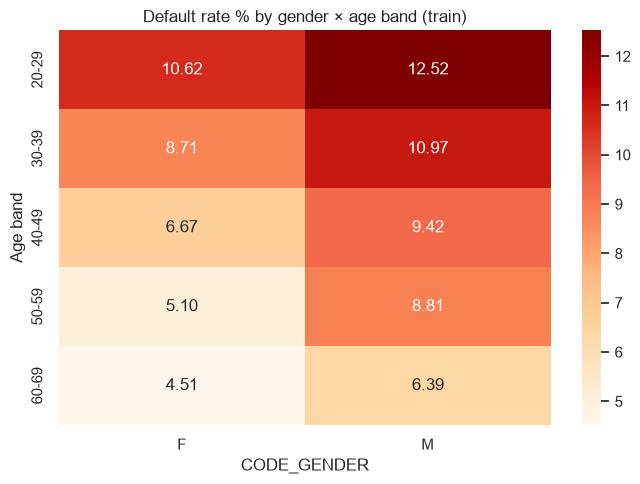

In [33]:
fig, ax = plt.subplots(figsize=(7, 5))
rate_pivot = (
    audit.groupby([AGE_BAND_COL, GENDER_COL])[TARGET].mean().unstack(GENDER_COL).reindex(BAND_ORDER)
)
sns.heatmap(100 * rate_pivot, annot=True, fmt=".2f", cmap="OrRd", ax=ax)
ax.set_title("Default rate % by gender × age band (train)")
ax.set_xlabel(GENDER_COL)
ax.set_ylabel("Age band")
plt.tight_layout()
plt.show()


Default rate by intersection cell with 95% bootstrap intervals, plotted by age band with separate series for women and men and a dashed line for the overall rate.


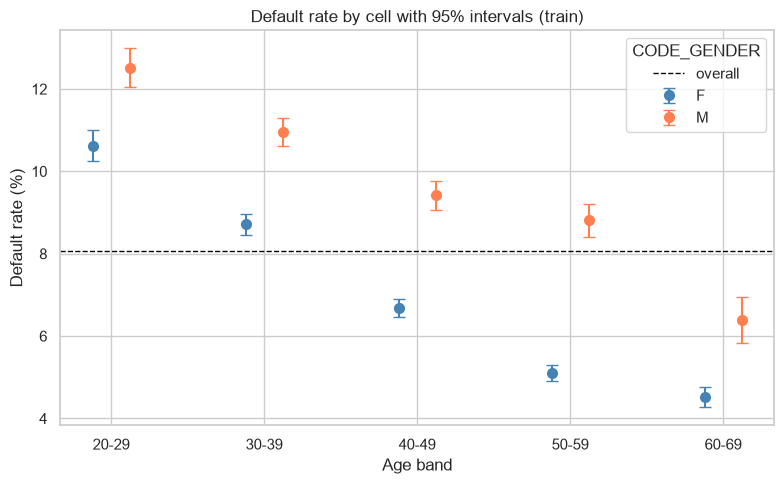

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(BAND_ORDER))
for offset, g in [(-0.12, "F"), (0.12, "M")]:
    sub = cell_rates.loc[[f"{g} | {b}" for b in BAND_ORDER]]
    ax.errorbar(
        x + offset, 100 * sub["rate"],
        yerr=[100 * (sub["rate"] - sub["ci_low"]), 100 * (sub["ci_high"] - sub["rate"])],
        fmt="o", ms=7, capsize=4, color=GENDER_COLORS[g], label=g,
    )
ax.axhline(100 * audit[TARGET].mean(), color="black", lw=1, ls="--", label="overall")
ax.set_xticks(x, BAND_ORDER)
ax.set_title("Default rate by cell with 95% intervals (train)")
ax.set_xlabel("Age band")
ax.set_ylabel("Default rate (%)")
ax.legend(title=GENDER_COL)
plt.tight_layout()
plt.show()


**Interpretation:**

- **Gender.** The default rate is 7.00% for women [6.89, 7.11] and 10.14% for men [9.96, 10.32]. The gap F − M is −3.14 pp [−3.36, −2.93]. Men default 1.45 times as often [1.41, 1.48]. On the favourable label the picture is very different: the repayment ratio M / F is 0.966 [0.964, 0.969], far above the 0.8 reference. Ratios on a rare outcome and on a common outcome describe the same gap very differently, which is why differences lead and ratios come second.
- **Age.** The default rate falls from 11.44% (20–29) to 4.92% (60–69), a gap of 6.53 pp [6.16, 6.90]: the age gap is about twice the gender gap.
- **Cells.** Men have the higher default rate in every age band, and default falls with age within each gender, by about 6.1 pp in both. The extremes are `M | 20-29` (12.52%) and `F | 60-69` (4.51%), a max−min gap of 8.01 pp [7.51, 8.56]. The ranking interleaves the two axes (`F | 20-29` ranks 3rd, above `M | 40-49`), so neither attribute alone orders the cells. This ranking is the reference for the base-rate vs TPR rank correlation in Step 6 (Wang et al. 2022).
- **Lum et al. correction.** The single-corrected between-cell SD (2.64 pp) is almost equal to the uncorrected one, because every cell has thousands of rows. At the data level the upward bias of the summaries is negligible. It will matter more in Step 6, where FNR and TPR rest on the positives only (486 in `M | 60-69`).
- **Reference for Step 6.** If a model approved exactly the applicants who repaid, its approval-rate ratio M / F would be 0.966. An approval-rate ratio well below that in Step 6 would mean the model's decisions separate the groups more than the labels do.

### 3.4 Gender gap after stratification

Women are older on average and default falls with age, so part of the F − M gap could reflect age composition. The gap is recomputed within each age band and within each PTI quintile and summarised with a Cochran-Mantel-Haenszel (CMH) test and common odds ratio. The 12 rows with missing `AMT_ANNUITY` are left out of the PTI analysis only.

Payment-to-income (PTI) quintiles on the training sample and a check that empirical cut points match the values fixed in `docs/decisions.md`. Rows with missing `AMT_ANNUITY` are excluded from PTI stratification only.


In [36]:
audit[PTI_COL] = audit["AMT_ANNUITY"] / audit["AMT_INCOME_TOTAL"]
pti_known = audit[PTI_COL].notna()
audit.loc[pti_known, PTI_Q_COL] = pd.qcut(
    audit.loc[pti_known, PTI_COL], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
).astype(str)
pti_cuts = audit.loc[pti_known, PTI_COL].quantile([0.2, 0.4, 0.6, 0.8]).to_numpy()
print(f"Rows without PTI (missing AMT_ANNUITY): {int((~pti_known).sum())}")
print(f"PTI quintile cut points: {np.round(pti_cuts, 3).tolist()} (decided: {PTI_DECIDED_CUTS})")
assert np.allclose(np.round(pti_cuts, 3), PTI_DECIDED_CUTS)


def gender_gap_within(df: pd.DataFrame, strata_col: str, strata_order: list) -> pd.DataFrame:
    rates = proportion_table(df, [strata_col, GENDER_COL], TARGET)
    pairs = [((s, "F"), (s, "M")) for s in strata_order]
    gaps = pairwise_gaps(rates, pairs)
    gaps.insert(0, strata_col, strata_order)
    return gaps.drop(columns=["group_a", "group_b"])


Rows without PTI (missing AMT_ANNUITY): 12
PTI quintile cut points: [0.104, 0.144, 0.186, 0.247] (decided: [0.104, 0.144, 0.186, 0.247])


Signed F − M gap in default rate within each 10-year age band, with 95% intervals and ratios.


In [37]:
gap_by_band = gender_gap_within(audit, AGE_BAND_COL, BAND_ORDER)
print("F − M default gap within each age band:")
display(gap_by_band.round(4))


F − M default gap within each age band:


,AGE_BAND,rate_a,rate_b,n_a,n_b,diff,diff_ci_low,diff_ci_high,p_value,ratio,ratio_ci_low,ratio_ci_high
0,20-29,0.1062,0.1252,25649,19535,-0.0190,-0.0249,-0.0130,0.0,0.8485,0.8061,0.8932
1,30-39,0.0871,0.1097,50119,32211,-0.0226,-0.0268,-0.0183,0.0,0.7943,0.7615,0.8284
2,40-49,0.0667,0.0942,49636,26963,-0.0275,-0.0316,-0.0233,0.0,0.7085,0.6743,0.7445
3,50-59,0.0510,0.0881,49350,18743,-0.0371,-0.0416,-0.0326,0.0,0.5790,0.5454,0.6147
4,60-69,0.0451,0.0639,27694,7607,-0.0188,-0.0248,-0.0127,0.0,0.7065,0.6382,0.7821


The same F − M default gap within each PTI quintile (applicants with known annuity only).


In [38]:
gap_by_pti = gender_gap_within(audit[pti_known], PTI_Q_COL, ["Q1", "Q2", "Q3", "Q4", "Q5"])
print("F − M default gap within each PTI quintile:")
display(gap_by_pti.round(4))


F − M default gap within each PTI quintile:


,PTI_QUINTILE,rate_a,rate_b,n_a,n_b,diff,diff_ci_low,diff_ci_high,p_value,ratio,ratio_ci_low,ratio_ci_high
0,Q1,0.0639,0.0835,36163,25337,-0.0195,-0.0238,-0.0153,0.0,0.7659,0.7236,0.8106
1,Q2,0.0656,0.1000,38824,22680,-0.0344,-0.0390,-0.0298,0.0,0.6563,0.6217,0.6928
2,Q3,0.0695,0.1032,40082,21411,-0.0337,-0.0385,-0.0289,0.0,0.6736,0.6387,0.7105
3,Q4,0.0742,0.1137,41588,19934,-0.0395,-0.0446,-0.0344,0.0,0.6524,0.6196,0.6869
4,Q5,0.0751,0.1144,45783,15693,-0.0393,-0.0449,-0.0338,0.0,0.6563,0.6218,0.6928


Row-normalized distribution of PTI quintiles by gender, to see whether men and women sit in different affordability bands.


In [ ]:
print("PTI quintile shares by gender (row-normalized, train):")
display(pd.crosstab(audit[GENDER_COL], audit[PTI_Q_COL], normalize="index").round(3))


Cochran–Mantel–Haenszel common odds ratio of default (men vs women) under several stratifications, with the CMH χ² test.


In [39]:
cmh_results = pd.DataFrame(
    {
        "unstratified (one stratum)": cmh_test(audit.assign(_all="all"), GENDER_COL, TARGET, "_all", "M"),
        "stratified by age band": cmh_test(audit, GENDER_COL, TARGET, AGE_BAND_COL, "M"),
        "stratified by PTI quintile": cmh_test(audit[pti_known], GENDER_COL, TARGET, PTI_Q_COL, "M"),
        "stratified by age band × PTI quintile": cmh_test(
            audit[pti_known].assign(_s=lambda d: d[AGE_BAND_COL] + " / " + d[PTI_Q_COL]),
            GENDER_COL, TARGET, "_s", "M",
        ),
    }
).T
print("Mantel-Haenszel odds ratio of default, M vs F, and CMH test:")
display(cmh_results.round(4))


Mantel-Haenszel odds ratio of default, M vs F, and CMH test:


,k_strata,mh_odds_ratio,cmh_chi2,p_value
unstratified (one stratum),1.0,1.4997,920.4261,0.0
stratified by age band,5.0,1.3892,597.1844,0.0
stratified by PTI quintile,5.0,1.5281,998.3062,0.0
stratified by age band × PTI quintile,25.0,1.4239,681.6705,0.0


Within–stratum F − M gaps by age band with 95% intervals; the dashed line is the unstratified gap on the full training sample.


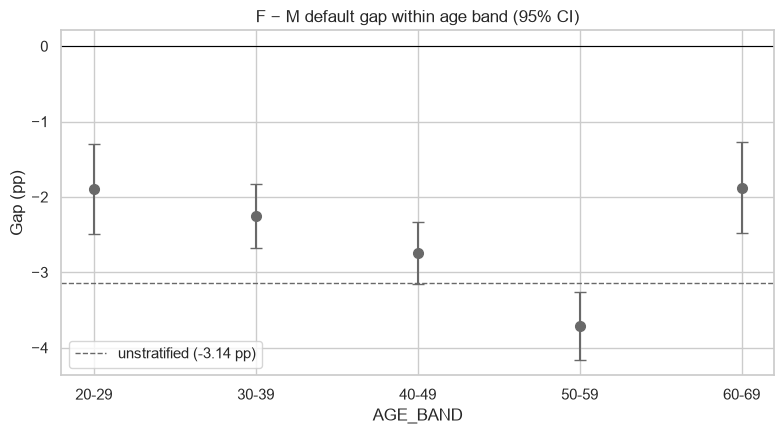

In [40]:
_gender_rates = proportion_table(audit, [GENDER_COL], TARGET).reindex(GENDER_ORDER)
_f, _m = _gender_rates.loc["F"], _gender_rates.loc["M"]
overall = 100 * proportion_gap(_f["rate"], _f["n"], _m["rate"], _m["n"])["diff"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(
    gap_by_band[AGE_BAND_COL], 100 * gap_by_band["diff"],
    yerr=[100 * (gap_by_band["diff"] - gap_by_band["diff_ci_low"]), 100 * (gap_by_band["diff_ci_high"] - gap_by_band["diff"])],
    fmt="o", ms=7, capsize=4, color="dimgray",
)
ax.axhline(0, color="black", lw=0.8)
ax.axhline(overall, color="dimgray", lw=1, ls="--", label=f"unstratified ({overall:.2f} pp)")
ax.set_title("F − M default gap within age band (95% CI)")
ax.set_xlabel(AGE_BAND_COL)
ax.set_ylabel("Gap (pp)")
ax.legend()
plt.tight_layout()
plt.show()


Within–stratum F − M gaps by PTI quintile with the same unstratified reference line.


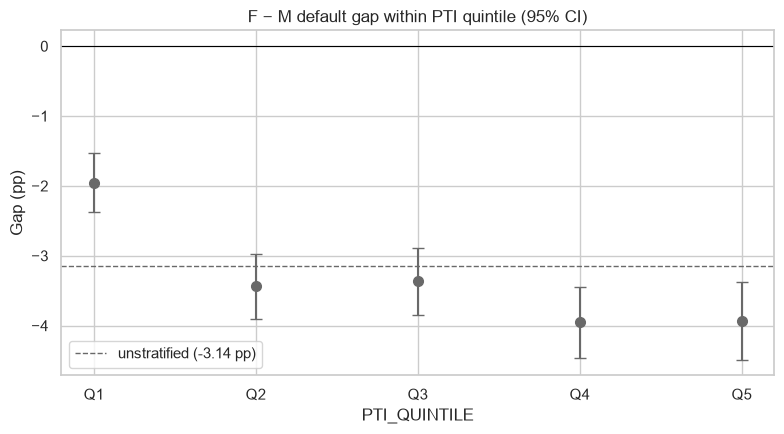

In [41]:
_gender_rates = proportion_table(audit, [GENDER_COL], TARGET).reindex(GENDER_ORDER)
_f, _m = _gender_rates.loc["F"], _gender_rates.loc["M"]
overall = 100 * proportion_gap(_f["rate"], _f["n"], _m["rate"], _m["n"])["diff"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(
    gap_by_pti[PTI_Q_COL], 100 * gap_by_pti["diff"],
    yerr=[100 * (gap_by_pti["diff"] - gap_by_pti["diff_ci_low"]), 100 * (gap_by_pti["diff_ci_high"] - gap_by_pti["diff"])],
    fmt="o", ms=7, capsize=4, color="dimgray",
)
ax.axhline(0, color="black", lw=0.8)
ax.axhline(overall, color="dimgray", lw=1, ls="--", label=f"unstratified ({overall:.2f} pp)")
ax.set_title("F − M default gap within PTI quintile (95% CI)")
ax.set_xlabel(PTI_Q_COL)
ax.set_ylabel("Gap (pp)")
ax.legend()
plt.tight_layout()
plt.show()


**Interpretation:**

- **Age composition explains only a small part of the gender gap.** The F − M gap is negative in every age band, from −1.9 pp (20–29, 60–69) to −3.7 pp (50–59), and no interval reaches 0. The Mantel-Haenszel odds ratio of default for men vs women falls from 1.50 (unstratified) to 1.39 within age bands.
- **Affordability does not explain it either.** Men are concentrated in the low-PTI quintiles (24% of men vs 18% of women in Q1; 15% vs 23% in Q5), and default rises with PTI. Stratifying by PTI therefore widens the gap: −2.0 pp in Q1 and −3.4 to −4.0 pp in Q2–Q5, with an odds ratio of 1.53. Stratifying by both age band and PTI quintile gives 1.42.
- **Reading.** The gender difference in `TARGET` is not an artefact of age or of PTI. The data cannot say what does drive it (other features, a real difference in repayment, or the way the label and the sample were produced). The CMH p-values are 0 at this sample size and add nothing beyond the intervals.

## 4. Missingness and credit-history coverage

Check whether missing values, structural codes and missing credit history fall unevenly on some groups, and whether being missing is itself related to default. The feature pipeline imputes medians and adds missing indicators, so uneven missingness means imputed values carry more weight for some groups (Martínez-Plumed et al. 2021).

### 4.1 Application columns

Missing share per group for every application column with at least 1% missing (the `_MEDI` / `_MODE` building duplicates are left out, as in the pipeline), plus two structural codes: the `DAYS_EMPLOYED` sentinel and `ORGANIZATION_TYPE = XNA`.

Columns audited for missingness: 26
Missing share by gender and by youngest vs oldest band (top 20 columns by |20–29 − 60–69| gap):


,pct_missing_overall,pct_F,pct_M,gap_F_minus_M_pp,pct_20_29,pct_60_69,gap_20_29_minus_60_69_pp
DAYS_EMPLOYED_SENTINEL,18.01,22.36,9.62,12.75,0.30,83.26,-82.95
ORGANIZATION_TYPE_XNA,18.01,22.36,9.62,12.75,0.30,83.26,-82.95
OCCUPATION_TYPE,31.35,36.14,22.10,14.04,17.20,86.67,-69.47
EXT_SOURCE_1,56.38,54.73,59.56,-4.82,42.32,80.02,-37.70
OWN_CAR_AGE,65.99,77.79,43.25,34.55,63.52,81.57,-18.05
EXT_SOURCE_3,19.83,19.07,21.28,-2.20,26.81,19.85,6.96
AMT_REQ_CREDIT_BUREAU_YEAR,13.50,12.93,14.60,-1.66,19.97,13.31,6.66
AMT_REQ_CREDIT_BUREAU_QRT,13.50,12.93,14.60,-1.66,19.97,13.31,6.66
AMT_REQ_CREDIT_BUREAU_HOUR,13.50,12.93,14.60,-1.66,19.97,13.31,6.66
AMT_REQ_CREDIT_BUREAU_DAY,13.50,12.93,14.60,-1.66,19.97,13.31,6.66


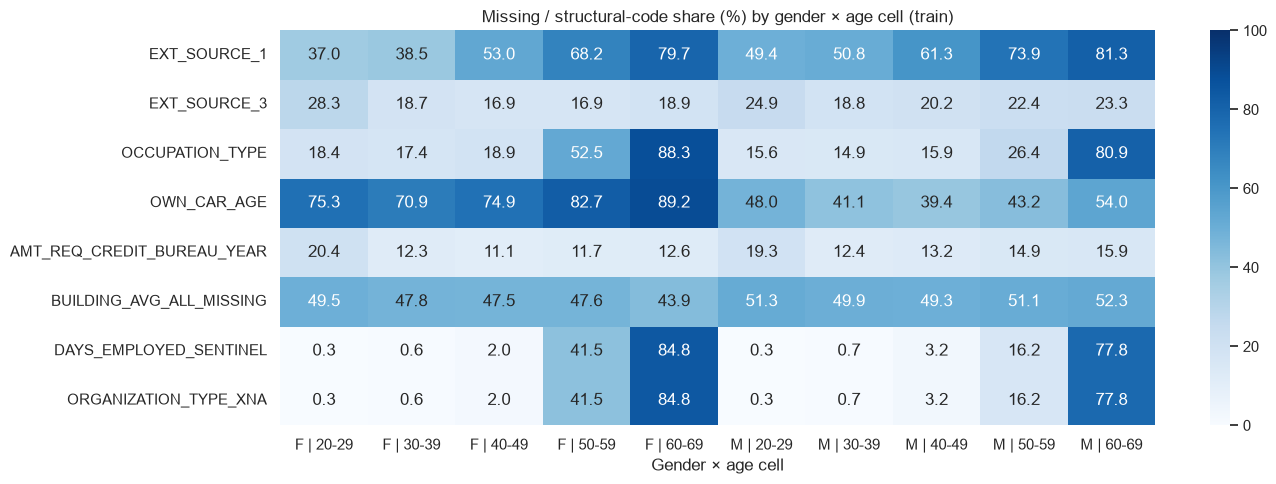

In [ ]:
app_cols = [
    c for c in train.columns
    if c not in {PRIMARY_KEY, TARGET} and not c.endswith(("_MEDI", "_MODE"))
]
missing_ind = audit[app_cols].isna()
missing_ind = missing_ind.loc[:, missing_ind.mean() >= 0.01]
missing_ind["DAYS_EMPLOYED_SENTINEL"] = audit["DAYS_EMPLOYED"] == DAYS_SENTINEL
missing_ind["ORGANIZATION_TYPE_XNA"] = audit["ORGANIZATION_TYPE"] == "XNA"
print(f"Columns audited for missingness: {missing_ind.shape[1]}")

miss_gender = missing_rate_by_group(missing_ind, audit[GENDER_COL])
miss_band = missing_rate_by_group(missing_ind, audit[AGE_BAND_COL])
missing_gaps = pd.DataFrame(
    {
        "pct_missing_overall": 100 * miss_gender["overall"],
        "pct_F": 100 * miss_gender["F"],
        "pct_M": 100 * miss_gender["M"],
        "gap_F_minus_M_pp": 100 * (miss_gender["F"] - miss_gender["M"]),
        "pct_20_29": 100 * miss_band["20-29"],
        "pct_60_69": 100 * miss_band["60-69"],
        "gap_20_29_minus_60_69_pp": 100 * (miss_band["20-29"] - miss_band["60-69"]),
    }
)
print(
    "Missing share by gender and by youngest vs oldest band (top 20 columns by |20–29 − 60–69| gap):"
)
display(
    missing_gaps.reindex(
        missing_gaps["gap_20_29_minus_60_69_pp"].abs().sort_values(ascending=False).index
    ).head(20).round(2)
)

building_avg = [c for c in missing_ind.columns if c.endswith("_AVG")]
missing_ind["BUILDING_AVG_ALL_MISSING"] = audit[building_avg].isna().all(axis=1)
focus_missing = [
    "EXT_SOURCE_1", "EXT_SOURCE_3", "OCCUPATION_TYPE", "OWN_CAR_AGE",
    "AMT_REQ_CREDIT_BUREAU_YEAR", "BUILDING_AVG_ALL_MISSING",
    "DAYS_EMPLOYED_SENTINEL", "ORGANIZATION_TYPE_XNA",
]
miss_cells = missing_rate_by_group(missing_ind[focus_missing], audit[INTERSECTION_COL])[CELL_ORDER]

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(100 * miss_cells, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=ax)
ax.set_title("Missing / structural-code share (%) by gender × age cell (train)")
ax.set_xlabel("Gender × age cell")
plt.tight_layout()
plt.show()

**Interpretation:**

- **The largest gaps are structural, not random.** `OWN_CAR_AGE` is missing when the applicant has no car: 77.8% of women vs 43.2% of men. `OCCUPATION_TYPE` is missing for 36.1% of women vs 22.1% of men. The `DAYS_EMPLOYED` sentinel and `ORGANIZATION_TYPE = XNA` mark the same rows (pensioners and non-employed): 22.4% of women vs 9.6% of men.
- **Concentrated in older cells.** The sentinel covers 84.8% of `F | 60-69` and 77.8% of `M | 60-69`, and `OCCUPATION_TYPE` is missing for 88.3% of `F | 60-69`. Most of the gender gap in these codes comes from women being older and more often pensioners.
- **`EXT_SOURCE_1`** is missing more often with age (37.0% in `F | 20-29` to 81.3% in `M | 60-69`), and more often for men in every band. `EXT_SOURCE_3` and the `AMT_REQ_CREDIT_BUREAU_*` block are missing most often for 20–29 (about 20–28%).
- **Building information** is missing for about half of applicants in every cell (gaps under 3 pp), so it carries little group information.
- The feature pipeline replaces these values with the training median and adds a missing indicator. For some groups, then, the model sees far more imputed constants than for others, and the indicators themselves carry group information (see §5.3).

### 4.2 Credit-history coverage

Share of applicants with at least one record in each child table, taken from the `HAS_*_HISTORY` flags of the engineered features. Applicants without bureau history are "thin-file" applicants whose features are mostly imputed.

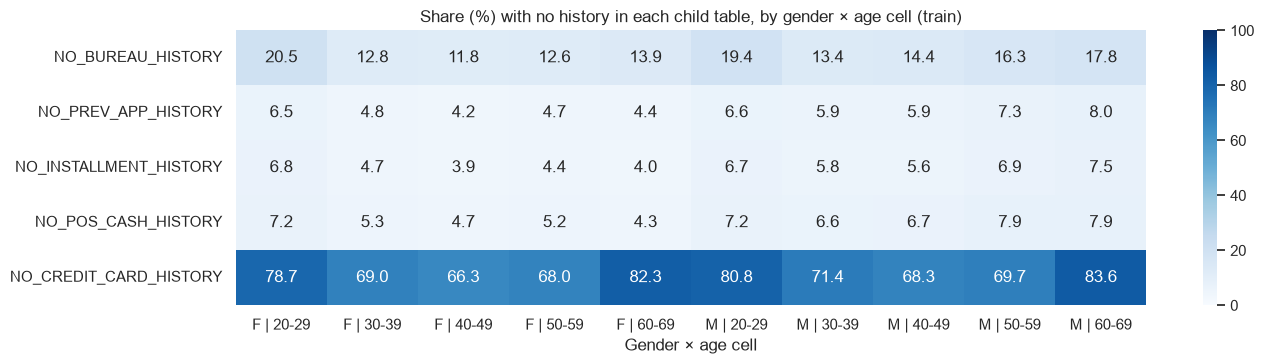

In [43]:
history_flags = [
    "num__HAS_BUREAU_HISTORY", "num__HAS_PREV_APP_HISTORY", "num__HAS_INSTALLMENT_HISTORY",
    "num__HAS_POS_CASH_HISTORY", "num__HAS_CREDIT_CARD_HISTORY",
]
ids_train = pd.read_parquet(FEATURES_DIR / "ids_train.parquet")
history = pd.read_parquet(FEATURES_DIR / "X_train.parquet", columns=history_flags)
history.columns = [c.replace("num__", "") for c in history.columns]
history[PRIMARY_KEY] = ids_train[PRIMARY_KEY].to_numpy()
history = audit[[PRIMARY_KEY]].merge(history, on=PRIMARY_KEY, how="left", validate="one_to_one")
assert history.drop(columns=PRIMARY_KEY).notna().all().all()
has_cols = [c for c in history.columns if c.startswith("HAS_")]
no_history = (history[has_cols] == 0).rename(columns=lambda c: c.replace("HAS_", "NO_"))

no_hist_cells = missing_rate_by_group(no_history, audit[INTERSECTION_COL])[CELL_ORDER]
fig, ax = plt.subplots(figsize=(14, 3.8))
sns.heatmap(100 * no_hist_cells, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=ax)
ax.set_title("Share (%) with no history in each child table, by gender × age cell (train)")
ax.set_xlabel("Gender × age cell")
plt.tight_layout()
plt.show()

**Interpretation:** Coverage differs less across groups than the application-level missingness. Men lack bureau history slightly more often than women (15.6% vs 13.6%). The youngest band is the most "thin-file": 20.5% of `F | 20-29` and 19.4% of `M | 20-29` have no bureau record, against 12–14% for women aged 30–69. Credit-card history is rare everywhere (28% overall) and rarest at both ends of the age range (17.5% in 60–69, 20.4% in 20–29). For these applicants, the child-table features are mostly imputed values, which ties model inputs to age.

### 4.3 Is missingness related to default?

Default rate with vs without a value, within each gender, for the focus columns and the missing-history flags. A gap that differs between women and men means the same missing value carries different information by group.

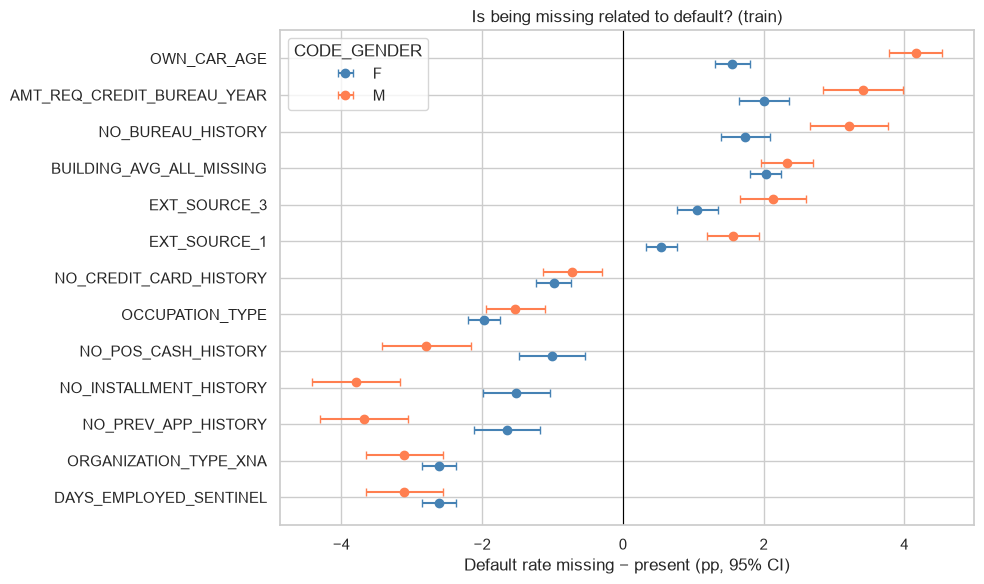

In [45]:
informative = outcome_by_missingness(
    pd.concat([missing_ind[focus_missing], no_history], axis=1),
    audit[TARGET],
    audit[GENDER_COL],
)

order = informative.groupby("column")["diff"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = {c: i for i, c in enumerate(order)}
for offset, g in [(-0.15, "F"), (0.15, "M")]:
    sub = informative[informative["group"] == g]
    ax.errorbar(
        100 * sub["diff"], [y_pos[c] + offset for c in sub["column"]],
        xerr=[100 * (sub["diff"] - sub["diff_ci_low"]), 100 * (sub["diff_ci_high"] - sub["diff"])],
        fmt="o", ms=6, capsize=3, color=GENDER_COLORS[g], label=g,
    )
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Default rate missing − present (pp, 95% CI)")
ax.set_title("Is being missing related to default? (train)")
ax.legend(title=GENDER_COL)
plt.tight_layout()
plt.show()

**Interpretation:** Missingness is related to default, and its relation differs by gender. Having no car (missing `OWN_CAR_AGE`) goes with a default rate 4.2 pp higher for men but only 1.5 pp higher for women. Having no bureau history goes with +3.2 pp for men vs +1.7 pp for women. Having no previous Home Credit application goes with −3.7 pp for men vs −1.6 pp for women. Being a pensioner or not employed (sentinel) goes with lower default for both (−2.6 pp F, −3.1 pp M). In this sense missingness is informative (not missing completely at random), and the same missing value means something different for women and men. A model that uses missing indicators can therefore treat the groups differently through these indicators, even with the gender column removed.

## 5. Proxies

Measure how strongly features encode gender or age: one column at a time, against the outcome, and jointly across all engineered features. A proxy is a concern when it carries group information and is also predictive of default, because a model can then reproduce group differences without using the protected attribute (Dwork et al. 2012, "redundant encoding"; Hurlin et al. 2024).

### 5.1 Pairwise associations with gender and age

The proxy audit of notebook 07: Cramér's V with gender and correlation ratio η with age for categorical candidates; Spearman correlation with age and the F vs M median for numeric candidates. The `DAYS_EMPLOYED` sentinel is set to missing, as in the feature pipeline.

Categorical proxy candidates (train):


,n_levels,pct_missing,cramers_v_gender,eta_age
column,,,,
OCCUPATION_TYPE,18,31.345,0.508,0.452
FLAG_OWN_CAR,2,0.000,0.346,0.130
ORGANIZATION_TYPE,58,0.000,0.337,0.637
NAME_INCOME_TYPE,8,0.000,0.170,0.620
NAME_FAMILY_STATUS,6,0.000,0.168,0.311
NAME_HOUSING_TYPE,6,0.000,0.066,0.246
NAME_EDUCATION_TYPE,5,0.000,0.026,0.200
REGION_RATING_CLIENT,3,0.000,0.019,0.011
NAME_CONTRACT_TYPE,2,0.000,0.009,0.086


Numeric proxy candidates (train):


,pct_missing,spearman_age,median_F,median_M
column,,,,
EXT_SOURCE_1,56.381,0.600,0.558,0.381
CNT_CHILDREN,0.000,-0.367,0.000,0.000
DAYS_EMPLOYED,18.007,-0.307,-1762.000,-1476.000
DAYS_REGISTRATION,0.000,-0.295,-4651.000,-4240.000
CNT_FAM_MEMBERS,0.001,-0.273,2.000,2.000
DAYS_ID_PUBLISH,0.000,-0.264,-3260.000,-3244.000
EXT_SOURCE_3,19.826,0.205,0.541,0.526
EXT_SOURCE_2,0.215,0.102,0.568,0.562
AMT_INCOME_TOTAL,0.000,-0.084,135000.000,180000.000


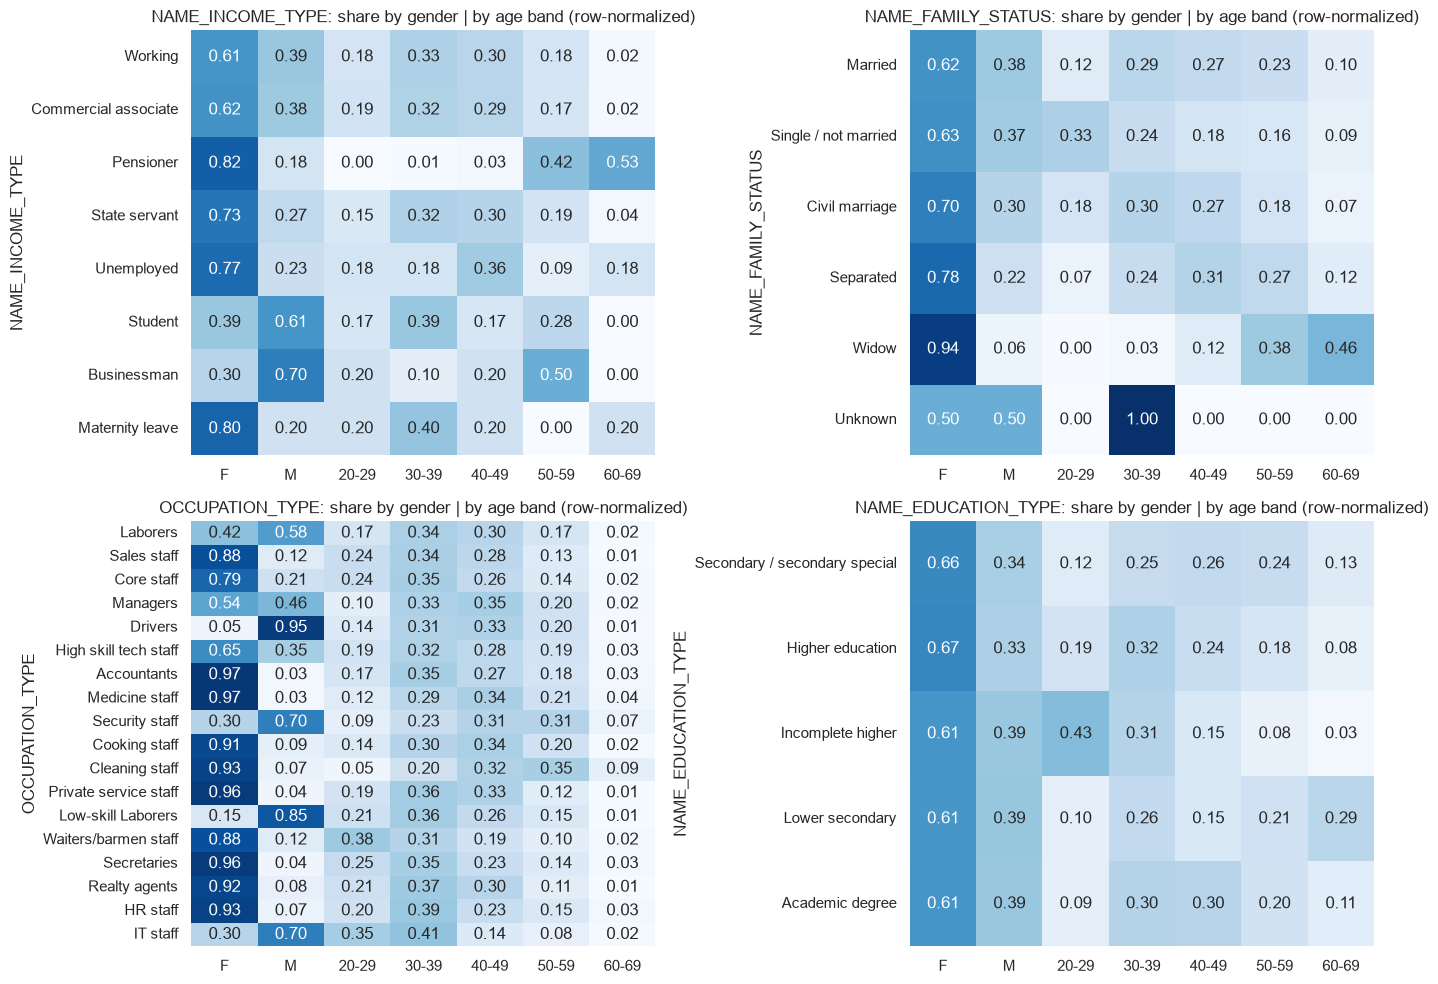

In [11]:
proxy_frame = audit.copy()
proxy_frame.loc[proxy_frame["DAYS_EMPLOYED"] == DAYS_SENTINEL, "DAYS_EMPLOYED"] = np.nan

categorical_assoc = pd.DataFrame(
    [
        {
            "column": col,
            "n_levels": proxy_frame[col].nunique(),
            "pct_missing": 100 * proxy_frame[col].isna().mean(),
            "cramers_v_gender": cramers_v(proxy_frame[col].fillna("__MISSING__"), proxy_frame[GENDER_COL]),
            "eta_age": correlation_ratio(proxy_frame[col].fillna("__MISSING__"), proxy_frame[AGE_YEARS_COL]),
        }
        for col in PROXY_CATEGORICAL
    ]
).set_index("column")

numeric_assoc = pd.DataFrame(
    [
        {
            "column": col,
            "pct_missing": 100 * proxy_frame[col].isna().mean(),
            "spearman_age": proxy_frame[[col, AGE_YEARS_COL]].corr(method="spearman").iloc[0, 1],
            "median_F": proxy_frame.loc[proxy_frame[GENDER_COL] == "F", col].median(),
            "median_M": proxy_frame.loc[proxy_frame[GENDER_COL] == "M", col].median(),
        }
        for col in PROXY_NUMERIC
    ]
).set_index("column")

print("Categorical proxy candidates (train):")
display(categorical_assoc.sort_values("cramers_v_gender", ascending=False).round(3))
print("Numeric proxy candidates (train):")
display(numeric_assoc.reindex(numeric_assoc["spearman_age"].abs().sort_values(ascending=False).index).round(3))

focus_cats = ["NAME_INCOME_TYPE", "NAME_FAMILY_STATUS", "OCCUPATION_TYPE", "NAME_EDUCATION_TYPE"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.ravel(), focus_cats):
    order = proxy_frame[col].value_counts().index
    gender_share = pd.crosstab(proxy_frame[col], proxy_frame[GENDER_COL], normalize="index").reindex(order)
    band_share = pd.crosstab(proxy_frame[col], proxy_frame[AGE_BAND_COL], normalize="index").reindex(order)
    sns.heatmap(
        pd.concat([gender_share, band_share], axis=1), annot=True, fmt=".2f",
        cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False,
    )
    ax.set_title(f"{col}: share by gender | by age band (row-normalized)")
    ax.set_xlabel("")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

**Interpretation:** The proxy ranking of notebook 07 is unchanged.

- **Gender proxies.** `OCCUPATION_TYPE` is the strongest (Cramér's V 0.51), followed by `FLAG_OWN_CAR` (0.35) and `ORGANIZATION_TYPE` (0.34). Education is only weakly associated with gender (0.03).
- **Age proxies.** `ORGANIZATION_TYPE` (η 0.64) and `NAME_INCOME_TYPE` (η 0.62) are driven by pensioners. Among numeric columns, `EXT_SOURCE_1` (Spearman 0.60, 56% missing), `CNT_CHILDREN` (−0.37) and the `DAYS_*` tenure fields follow.
- **Women and men differ in income.** The median income is 135,000 for women and 180,000 for men, which is one reason income alone is rejected as a conditioning variable (`docs/decisions.md`).

### 5.2 Association with the protected attribute vs with the outcome

Every application column is discretized (numeric columns into deciles, missing as its own category) and its Cramér's V is computed with gender, with the age band and with `TARGET`, so all columns share one 0–1 scale (as in Hurlin et al. 2024, Fig. 1). Columns high on both axes are the proxies that matter for a credit model.

Columns profiled: 85
Top 15 by association with gender:


,pct_missing,v_gender,v_age_band,v_target
column,,,,
OCCUPATION_TYPE,31.345,0.508,0.260,0.080
OWN_CAR_AGE,65.991,0.349,0.078,0.039
FLAG_OWN_CAR,0.000,0.346,0.152,0.022
ORGANIZATION_TYPE,0.000,0.337,0.365,0.072
FLAG_DOCUMENT_8,0.000,0.250,0.118,0.008
AMT_INCOME_TOTAL,0.000,0.215,0.089,0.027
EXT_SOURCE_1,56.381,0.210,0.246,0.104
DAYS_EMPLOYED,18.007,0.177,0.388,0.089
NAME_INCOME_TYPE,0.000,0.170,0.354,0.064


Top 15 by association with age band:


,pct_missing,v_gender,v_age_band,v_target
column,,,,
FLAG_EMP_PHONE,0.000,0.157,0.706,0.046
FLAG_DOCUMENT_6,0.000,0.101,0.465,0.029
DAYS_EMPLOYED,18.007,0.177,0.388,0.089
ORGANIZATION_TYPE,0.000,0.337,0.365,0.072
NAME_INCOME_TYPE,0.000,0.170,0.354,0.064
DAYS_ID_PUBLISH,0.000,0.043,0.328,0.053
OCCUPATION_TYPE,31.345,0.508,0.260,0.080
EXT_SOURCE_1,56.381,0.210,0.246,0.104
CNT_FAM_MEMBERS,0.001,0.071,0.246,0.016


Top 15 by association with TARGET:


,pct_missing,v_gender,v_age_band,v_target
column,,,,
EXT_SOURCE_3,19.826,0.037,0.099,0.165
EXT_SOURCE_2,0.215,0.018,0.069,0.157
EXT_SOURCE_1,56.381,0.210,0.246,0.104
DAYS_EMPLOYED,18.007,0.177,0.388,0.089
AMT_GOODS_PRICE,0.090,0.064,0.111,0.085
OCCUPATION_TYPE,31.345,0.508,0.260,0.080
ORGANIZATION_TYPE,0.000,0.337,0.365,0.072
NAME_INCOME_TYPE,0.000,0.170,0.354,0.064
REGION_RATING_CLIENT_W_CITY,0.000,0.019,0.018,0.061


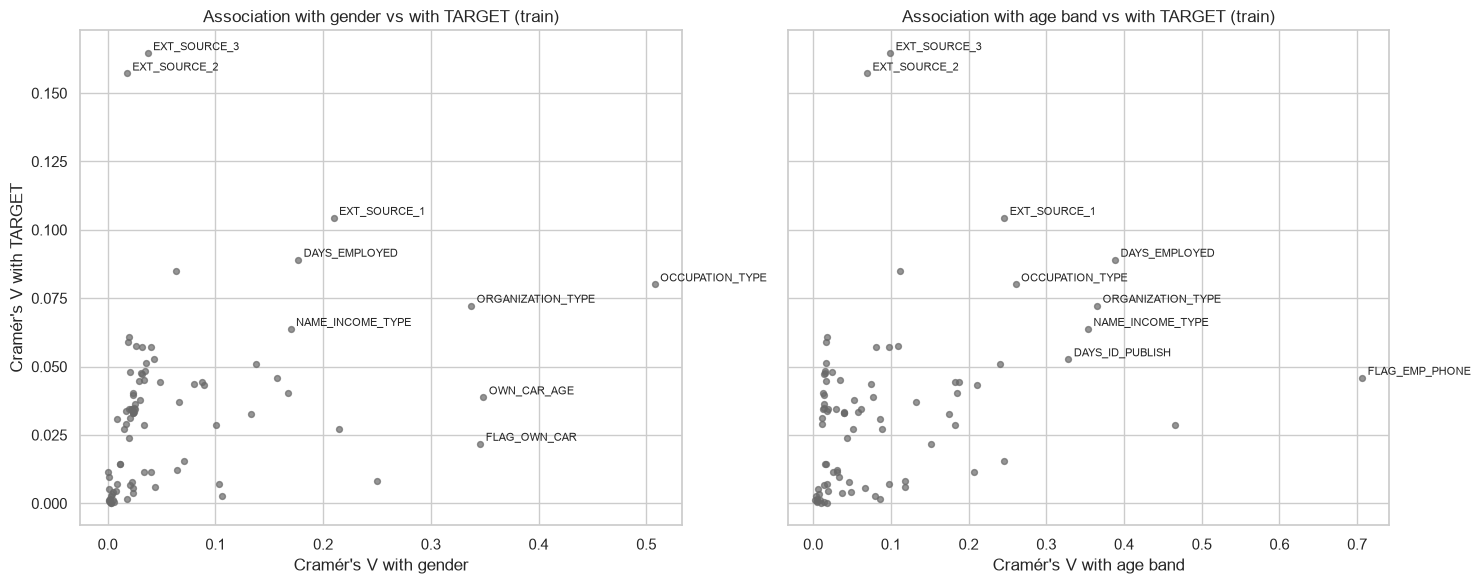

In [12]:
proxy_cols = [
    c for c in app_cols
    if c not in {GENDER_COL, "DAYS_BIRTH"} and c in proxy_frame.columns
]
assoc = association_profile(
    proxy_frame,
    proxy_cols,
    {
        "gender": proxy_frame[GENDER_COL],
        "age_band": proxy_frame[AGE_BAND_COL],
        "target": proxy_frame[TARGET],
    },
)
print(f"Columns profiled: {len(assoc)}")
print("Top 15 by association with gender:")
display(assoc.sort_values("v_gender", ascending=False).head(15).round(3))
print("Top 15 by association with age band:")
display(assoc.sort_values("v_age_band", ascending=False).head(15).round(3))
print("Top 15 by association with TARGET:")
display(assoc.sort_values("v_target", ascending=False).head(15).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, xcol, label in [(axes[0], "v_gender", "gender"), (axes[1], "v_age_band", "age band")]:
    ax.scatter(assoc[xcol], assoc["v_target"], s=18, color="dimgray", alpha=0.7)
    by_product = assoc.assign(score=assoc[xcol] * assoc["v_target"]).nlargest(7, "score").index
    by_target = assoc.nlargest(2, "v_target").index
    top = assoc.loc[by_product.union(by_target)]
    for name, row in top.iterrows():
        ax.annotate(name, (row[xcol], row["v_target"]), fontsize=8,
                    xytext=(4, 2), textcoords="offset points")
    ax.set_xlabel(f"Cramér's V with {label}")
    ax.set_title(f"Association with {label} vs with TARGET (train)")
axes[0].set_ylabel("Cramér's V with TARGET")
plt.tight_layout()
plt.show()

**Interpretation:**

- **The strongest predictors carry little group information.** `EXT_SOURCE_3` and `EXT_SOURCE_2` have the highest association with `TARGET` (V 0.165 and 0.157) and only weak association with gender (0.04, 0.02) or age band (0.10, 0.07).
- **The proxies that matter** are associated with both a protected attribute and the outcome: `EXT_SOURCE_1` (gender 0.21, age 0.25, target 0.10), `DAYS_EMPLOYED` (0.18, 0.39, 0.09), `OCCUPATION_TYPE` (0.51, 0.26, 0.08), `ORGANIZATION_TYPE` (0.34, 0.37, 0.07) and `NAME_INCOME_TYPE` (0.17, 0.35, 0.06).
- **Strong proxies with little outcome association.** `FLAG_OWN_CAR` / `OWN_CAR_AGE` (gender 0.35) and `FLAG_EMP_PHONE` (age band 0.71, pensioners have no employer phone) are strong proxies but carry little outcome information on their own.
- **Not an exclusion list.** This is a list of features to watch when explaining Step 6 disparities. Hardt et al. (2016, §6.1) show that a proxy and a legitimate predictor correlated with the attribute cannot be told apart from the joint distribution alone.

### 5.3 Joint predictability of gender (Feldman et al. 2015)

An auxiliary LightGBM classifier predicts gender (M = 1) from all engineered features with the protected columns (`cat__CODE_GENDER_*`, `num__DAYS_BIRTH`) removed, using the credit model's CV setup and hyperparameters (`configs/model.yaml`). The code lives in the helper module. Its out-of-fold balanced error rate (BER) measures how much gender is encoded jointly in the remaining features. Feldman et al. show that a data set admits disparate impact at the four-fifths rule if and only if the protected attribute can be predicted with BER below `1/2 − β/8`, where β is the favourable-outcome share of the protected group; here β is the repayment rate (`TARGET = 0`) of the group treated as protected.

Protected columns removed: ['num__DAYS_BIRTH', 'cat__CODE_GENDER_F', 'cat__CODE_GENDER_M']
Features used: 490


Out-of-fold predictability of gender from the non-protected features:


,value
oof_roc_auc,0.9065
fold_auc_min,0.9051
fold_auc_max,0.9078
min_ber,0.1750
min_ber_threshold,0.3508
ber_at_prevalence_threshold,0.1752
feldman_threshold_protected_F,0.3837
feldman_threshold_protected_M,0.3877
ber_if_unpredictable,0.5000


Top 20 features for predicting gender (mean gain over folds):


,feature,mean_gain
0,cat__OCCUPATION_TYPE_Drivers,209383.1
1,cat__FLAG_OWN_CAR_N,152964.8
2,cat__OCCUPATION_TYPE_Laborers,146848.4
3,num__OWN_CAR_AGE_MISSING,108769.4
4,num__EXT_SOURCE_1,90844.3
5,num__AMT_INCOME_TOTAL,69419.8
6,num__FLAG_DOCUMENT_8,53966.7
7,cat__OCCUPATION_TYPE_Security staff,42879.1
8,cat__OCCUPATION_TYPE_Accountants,34395.6
9,cat__OCCUPATION_TYPE_Low-skill Laborers,30217.3


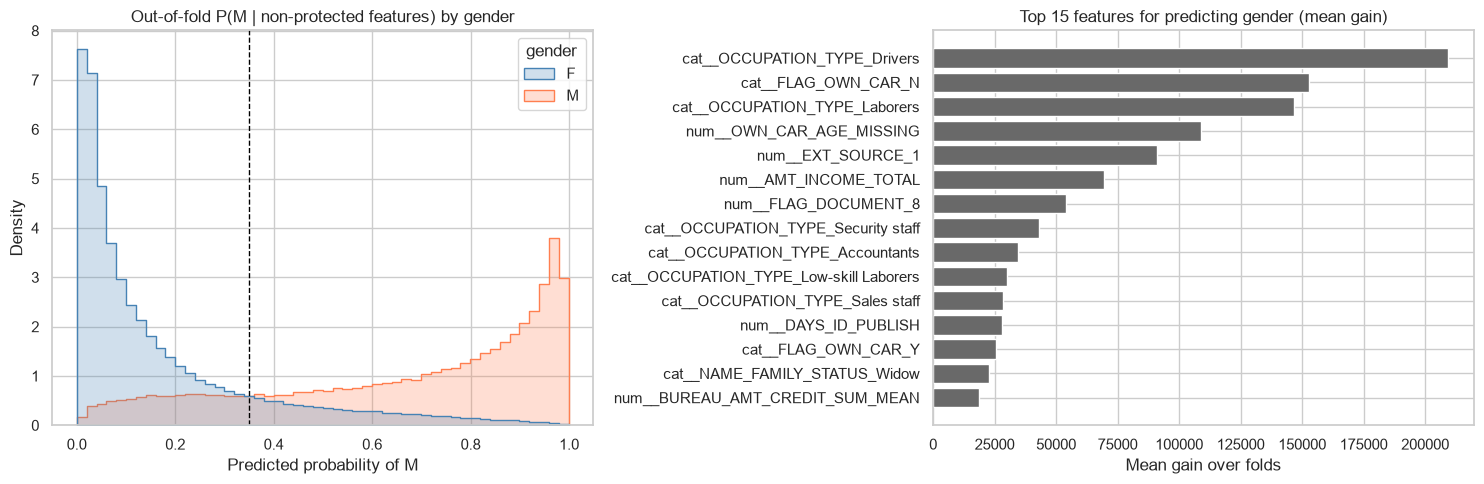

In [13]:
X_train = pd.read_parquet(FEATURES_DIR / "X_train.parquet")
assert len(X_train) == len(ids_train)
x_order = ids_train[[PRIMARY_KEY]].merge(audit[[PRIMARY_KEY, GENDER_COL]], on=PRIMARY_KEY, how="left")
assert x_order[GENDER_COL].notna().all()

protected_feature_cols = [
    c for c in X_train.columns if c.startswith("cat__CODE_GENDER_") or c == "num__DAYS_BIRTH"
]
print(f"Protected columns removed: {protected_feature_cols}")
print(f"Features used: {X_train.shape[1] - len(protected_feature_cols)}")

gender_pred = protected_attribute_predictability(
    X_train,
    x_order[GENDER_COL],
    ids_train[PRIMARY_KEY],
    model_config,
    positive_label="M",
    drop_columns=protected_feature_cols,
)
del X_train

beta = {g: 1 - gender_rates.loc[g, "rate"] for g in GENDER_ORDER}
predictability = pd.Series(
    {
        "oof_roc_auc": gender_pred.roc_auc,
        "fold_auc_min": min(gender_pred.fold_roc_aucs),
        "fold_auc_max": max(gender_pred.fold_roc_aucs),
        "min_ber": gender_pred.min_ber,
        "min_ber_threshold": gender_pred.min_ber_threshold,
        "ber_at_prevalence_threshold": gender_pred.ber_at_prevalence,
        "feldman_threshold_protected_F": feldman_ber_threshold(beta["F"]),
        "feldman_threshold_protected_M": feldman_ber_threshold(beta["M"]),
        "ber_if_unpredictable": 0.5,
    }
)
print("Out-of-fold predictability of gender from the non-protected features:")
display(predictability.round(4).to_frame("value"))

importance = gender_pred.importance_gain.head(20)
print("Top 20 features for predicting gender (mean gain over folds):")
display(importance.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
oof = gender_pred.oof.assign(gender=np.where(gender_pred.oof["ATTRIBUTE"] == 1, "M", "F"))
sns.histplot(data=oof, x="y_pred_proba", hue="gender", hue_order=GENDER_ORDER, palette=GENDER_COLORS,
             bins=50, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].axvline(gender_pred.min_ber_threshold, color="black", lw=1, ls="--", label="min-BER threshold")
axes[0].set_title("Out-of-fold P(M | non-protected features) by gender")
axes[0].set_xlabel("Predicted probability of M")
imp_plot = importance.head(15).iloc[::-1]
axes[1].barh(imp_plot["feature"], imp_plot["mean_gain"], color="dimgray")
axes[1].set_title("Top 15 features for predicting gender (mean gain)")
axes[1].set_xlabel("Mean gain over folds")
plt.tight_layout()
plt.show()

**Interpretation:**

- **Gender is strongly encoded in the other features.** Without the gender and age columns, the auxiliary classifier predicts gender with an out-of-fold AUC of 0.907 (folds 0.905–0.908) and a minimum BER of 0.175, far below 0.5 (no information). The most useful features are occupation dummies (Drivers, Laborers, Security staff, Accountants), car ownership and its missing flag, `EXT_SOURCE_1`, income, `FLAG_DOCUMENT_8` and `NAME_FAMILY_STATUS = Widow`.
- **Feldman et al.'s test.** Their threshold is 0.384 with women as the protected group and 0.388 with men. The BER of 0.175 is well below both, so by their Thm. 4.1 the data admits disparate impact at the four-fifths rule. A better classifier could only lower the BER, so this conclusion does not depend on the choice of LightGBM.
- **What it does and does not mean.** Dropping `CODE_GENDER` from the model would not remove gender information (Dwork et al. 2012, "redundant encoding"; Hurlin et al. 2024 find the same). The test does not say that a credit model trained on `TARGET` will produce disparate impact. It says only that the features would allow it. Whether it happens is measured in Step 6.

## 6. What the data does and does not imply

Bring the findings together and state, for each one, what it shows, what it cannot show about historical bias, and where it is used later.

| Finding | What it shows | What it does not show | Used in |
| --- | --- | --- | --- |
| Men default more: 10.14% vs 7.00% (F − M −3.14 pp [−3.36, −2.93]). The gap holds in every age band and PTI quintile (MH odds ratio 1.39–1.53). | `TARGET` differs by gender, and not only through age composition or affordability. | Whether the gap reflects a real difference in repayment, a biased or proxy label, or Home Credit's past approval policy. The labels do not point to a historical disadvantage of women: in them, men are the higher-risk group. | Step 6: base rates drive the error-rate trade-off; with a calibrated score, men are expected to have the higher FPR and lower FNR (Chouldechova 2017, §3). |
| Default falls with age (11.44% → 4.92%). Cells range from 4.51% to 12.52% (max−min 8.01 pp; corrected SD 2.64 pp). | Age is the larger axis, and the intersectional spread exceeds either attribute alone. | Why younger applicants default more (income, tenure, life stage). | Step 6: cell ranking for Kendall's τ; the pre-specified cell pairs. |
| Women are 65.8% of applicants, are older, and make up 78.5% of 60–69. The smallest cell is `M \| 60-69` (486 positives). | Gender and age are confounded, and the oldest men are the thinnest cell. | Under- or over-representation relative to the population: there is no benchmark. | Step 6: interval widths; reporting by cell. |
| Missingness is structural and uneven: no car 78% F vs 43% M; pensioner codes 22% F vs 10% M, up to 85% in 60–69; `EXT_SOURCE_1` missing rises with age; 20% of 20–29 have no bureau record. Missing values relate to default differently by gender. | Imputed values and missing flags carry group information into the model. | That data collection discriminated. Most gaps follow life circumstances (car ownership, retirement, a short credit history). | Step 6 explanations; pre-processing candidates (Phase 2). |
| Gender is predictable from the non-protected features (AUC 0.907, BER 0.175 < Feldman threshold 0.384). The main proxies are occupation, car ownership, `EXT_SOURCE_1`, income and `DAYS_EMPLOYED`. | Removing gender would not remove gender information. The data admits disparate impact at the four-fifths rule. | That a model trained on `TARGET` produces disparate impact, or that using these features is illegitimate. | Supports keeping gender in `X` and auditing outcomes; Feldman et al.'s repair as a pre-processing candidate. |

**Limits on any claim about historical bias.**

1. **Observational data cannot separate causes.** Two causal stories can produce the same joint distribution, one where a feature acts as a proxy and one where it is a legitimate predictor (Hardt et al. 2016, §6.1).
2. **`TARGET` is a constructed label** ("payment difficulties"; Barocas et al.). Error-rate criteria take it as correct (Wachter et al. 2021, §3.2: "bias preserving"), so any bias already in the label passes unseen into the model audit.
3. **Selective labels.** In our reading, `TARGET` exists only for loans that were granted, so every gap above is conditional on Home Credit's past approval decisions. Rejected applicants are missing (Wachter et al. 2021, §3.3).
4. **Direction.** The label gap goes against men. A model that learns it will approve men less often. Whether that is a harm or a correct risk difference cannot be decided from the data.

**Conclusion for Step 5.** The raw data shows clear, stable group differences in outcomes, in missingness and in the information the features carry about gender and age. They are consistent with structural inequalities (occupational segregation, retirement, a short credit history at young ages) and with a label shaped by past lending. The data alone cannot show that they come from historical bias. What it does establish is the baseline Step 6 needs to say whether a model preserves, amplifies or reduces these differences.

## 7. Summary of findings

- **Sample:** 307,507 train rows after dropping 4 `XNA` rows. The groups match `fairness_groups_train.parquet` exactly.
- **Representation:** 65.8% women. Women are older, and their share rises from 56.8% (20–29) to 78.5% (60–69). The smallest cell is `M | 60-69` (7,607 rows, 486 positives). Train and test mixes differ by at most 1.2 pp.
- **Outcomes:** default F 7.00% vs M 10.14% (gap −3.14 pp [−3.36, −2.93]; ratio M / F 1.45; repayment ratio M / F 0.966). Age gap 20–29 − 60–69: 6.53 pp. Cells span 4.51–12.52% (max−min 8.01 pp [7.51, 8.56]); Lum's correction is negligible at the data level.
- **Stratified:** the gender gap holds in every age band and PTI quintile (MH odds ratio 1.50 unstratified, 1.39 by age band, 1.53 by PTI, 1.42 by both).
- **Missingness:** structural and uneven. No car 77.8% F vs 43.2% M; pensioner codes 22.4% F vs 9.6% M, up to 85% of 60–69; `EXT_SOURCE_1` missing 37–81% rising with age; no bureau record for about 20% of 20–29. Missingness relates to default, and more strongly for men.
- **Proxies:** `OCCUPATION_TYPE` (V 0.51), car ownership, `ORGANIZATION_TYPE`, `NAME_INCOME_TYPE`, `EXT_SOURCE_1` and `DAYS_EMPLOYED` carry gender or age information and outcome information. Jointly, gender is predictable with AUC 0.907 and BER 0.175, well below Feldman et al.'s threshold of 0.384.
- **Implication:** the data shows group differences that a model will learn. It cannot attribute them to historical bias (observational data, a constructed and selectively observed label). Step 6 measures whether the baseline model preserves, amplifies or reduces them.